[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shuishen112/neural-networks/blob/main/language_models/07_char_rnn.ipynb)

# LM 7 — A character-level RNN language model on Shakespeare

*Companion to Lecture 7 — Recurrent Neural Networks.*

In Lecture 7 we trained a small character LSTM on a few paragraphs of text. Here we do it
properly: on a real corpus (1.1 M characters of Shakespeare), with the batching scheme that
makes recurrent networks practical on long text (**truncated backpropagation through time
with a carried hidden state**), with a held-out validation set measured in nats and bits per
character, and with a fair comparison of the vanilla RNN, the GRU and the LSTM. We then look
at how text is *generated* (temperature, top-$k$, prompting) and peek *inside* the network.
Every one of these ideas — streaming a long document through a model with a fixed budget,
carrying a state, sampling strategies, interpretability of individual units — reappears in
large language models.

> **Language-model track:** 1 Bigram · 2 MLP LM · 3 Training dynamics · 4 PyTorch · 5 Word-level & regularisation · 6 WaveNet · **7 Char-RNN** · 8 GPT · 9 Sequence VAE · 10 Diffusion LM

In [1]:
import math
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
np.random.seed(0)
torch.set_num_threads(2)
device = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams["figure.figsize"] = (5, 4)
plt.rcParams["axes.grid"] = True
print("torch", torch.__version__, "| device:", device)

torch 2.14.1+cpu | device: cpu


In [2]:
from pathlib import Path
import urllib.request

def load_text(name):
    """Load a corpus from ../data (repository checkout) or download it (e.g. on Colab)."""
    for folder in (Path("data"), Path("../data")):
        if (folder / name).exists():
            return (folder / name).read_text(encoding="utf-8")
    url = f"https://raw.githubusercontent.com/shuishen112/neural-networks/main/data/{name}"
    return urllib.request.urlopen(url).read().decode("utf-8")

## 1. The data: characters as tokens

The corpus is a single long string. A **character-level** model uses every distinct character
as a token, so the vocabulary is tiny (65 symbols: letters, digits, punctuation, space and
newline) and *any* string over those characters can be represented — there is no
"unknown word" problem as in the word-level model of LM 5. The price is long sequences: a
sentence is ~5× more characters than words, so the model has to carry information over many
more steps.

We split by position, as everywhere in this track: the first 90 % of the characters for
training, the last 10 % for validation. (A positional split is the honest choice for text:
random windows from the same play would leak character names and phrases into the
validation set.)

In [3]:
text = load_text("tinyshakespeare.txt")
chars = sorted(set(text))
V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}

def encode(s):
    return [stoi[c] for c in s]

def decode(ids):
    return "".join(itos[i] for i in ids)

n_train = int(0.9 * len(text))
train_text, val_text = text[:n_train], text[n_train:]
train_ids = torch.tensor(encode(train_text), dtype=torch.long)
val_ids = torch.tensor(encode(val_text), dtype=torch.long)
assert decode(encode("ROMEO:\nO, she doth teach!")) == "ROMEO:\nO, she doth teach!"

print(f"{len(text):,} characters; train {len(train_ids):,}, val {len(val_ids):,}")
print(f"vocabulary of V = {V}: {''.join(chars)!r}")
print("-" * 40)
print(train_text[:250])

1,115,394 characters; train 1,003,854, val 111,540
vocabulary of V = 65: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
----------------------------------------
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



Two reference points for the validation loss (in **nats per character**, the mean
cross-entropy $-\frac1N\sum_t \ln p(c_t \mid c_{<t})$):

* uniform guessing: $\ln V = \ln 65 \approx 4.17$;
* a **unigram** model that ignores context and uses the character frequencies: its loss is the
  cross-entropy between validation and training frequencies.

Dividing by $\ln 2$ converts nats to **bits per character** (bpc), the unit used in the
compression literature: a model with $b$ bpc could compress the text to $b/8$ bytes per character
with an arithmetic coder.

In [4]:
train_freq = torch.bincount(train_ids, minlength=V).float() + 1.0         # add-one smoothing
p_unigram = train_freq / train_freq.sum()
unigram_nll = -torch.log(p_unigram[val_ids]).mean().item()
print(f"uniform : {math.log(V):.3f} nats/char = {math.log(V) / math.log(2):.2f} bits/char")
print(f"unigram : {unigram_nll:.3f} nats/char = {unigram_nll / math.log(2):.2f} bits/char")

uniform : 4.174 nats/char = 6.02 bits/char
unigram : 3.347 nats/char = 4.83 bits/char


## 2. Batching a long text: parallel tracks and truncated BPTT

In Lecture 7 we drew **random windows** of 64 characters and started each from a zero hidden
state. That wastes the main strength of an RNN — its state can, in principle, summarise an
unbounded past — because the model never sees more than 64 characters of context. The
classical recipe for long text (used for every RNN language model before Transformers) is:

1. **Parallel tracks.** Cut the training stream into $B$ contiguous pieces of length
   $L = \lfloor N/B \rfloor$ and stack them into a $(B, L)$ matrix. Row $b$ is a long, coherent
   piece of text; the $B$ rows are processed in parallel (they are the batch).
2. **Chunks.** Walk through the matrix from left to right in chunks of $T$ columns. Chunk $i$
   has inputs $X_i = $ columns $[iT, (i+1)T)$ and targets $Y_i = $ columns $[iT+1, (i+1)T+1)$
   — the inputs shifted by one.
3. **Carry the state.** The final hidden state of chunk $i$ is the initial state of chunk $i+1$,
   so row $b$ of chunk $i+1$ really continues where row $b$ of chunk $i$ stopped.
4. **Truncate the gradient.** Before processing chunk $i+1$ we **detach** the state: its *value*
   is kept, but the autograd graph that produced it is cut. Backpropagation therefore runs
   through at most $T$ time steps (**truncated BPTT**).

Here is the scheme on a toy "text" (the alphabet) with $B=3$ tracks and chunks of $T=4$:

In [5]:
def make_tracks(ids, B):
    """(N,) -> (B, L): row b is the contiguous piece ids[b*L:(b+1)*L]."""
    L = len(ids) // B
    return ids[: B * L].view(B, L)

def get_chunk(tracks, i, T):
    """Inputs = columns [iT, (i+1)T), targets = the same columns shifted by one."""
    x = tracks[:, i * T:(i + 1) * T]
    y = tracks[:, i * T + 1:(i + 1) * T + 1]
    return x, y

toy = torch.arange(26)
toy_tracks = make_tracks(toy, 3)
n_toy_chunks = (toy_tracks.size(1) - 1) // 4          # the last target column must exist
print("tracks:", ["".join(chr(97 + j) for j in row) for row in toy_tracks.tolist()])
for i in range(n_toy_chunks):
    x, y = get_chunk(toy_tracks, i, 4)
    print(f"chunk {i}:  x =", ["".join(chr(97 + j) for j in r) for r in x.tolist()],
          "  y =", ["".join(chr(97 + j) for j in r) for r in y.tolist()])

tracks: ['abcdefgh', 'ijklmnop', 'qrstuvwx']
chunk 0:  x = ['abcd', 'ijkl', 'qrst']   y = ['bcde', 'jklm', 'rstu']


Read the columns: track 0 is `abcdefgh`; chunk 0 feeds `abcd` and asks for `bcde`, chunk 1
feeds `efgh` *starting from the state left behind after `d`*. Within a chunk all targets are
predicted in parallel from one forward pass of the RNN; across chunks the RNN state is the only
thing that connects them.

**Why detach, and why not simply reset?** Three options exist for the state at a chunk boundary:

| at the boundary | context seen by the model | backprop length | cost per chunk |
|---|---|---|---|
| reset to $\mathbf{0}$ | $\le T$ characters | $\le T$ | $O(T)$ |
| carry **and detach** (truncated BPTT) | unbounded (in principle) | $\le T$ | $O(T)$ |
| carry, keep the graph | unbounded | everything since the start | grows linearly — infeasible |

Carrying and detaching gives the model long context in the *forward* pass while keeping the
*backward* pass cheap. The cost is a bias: the gradient never "sees" how a parameter change
would have affected the state at the start of the chunk, so the network is not *explicitly*
trained to store information for more than $T$ steps. In practice it still learns to carry
useful information further (we will measure this in Section 5), because whatever it stores
for $T$ steps it tends to keep.

If you forget the detach, PyTorch will tell you: after `loss.backward()` the graph of the
previous chunk has been freed, and the next backward pass would have to run through it.

## 3. The model

Embedding $\to$ recurrent layer $\to$ linear head, exactly as in Lecture 7, but parameterised by
the cell type so we can compare cells later. Shapes with `batch_first=True`:

* input `idx`: $(B, T)$ integers; embedding: $(B, T, E)$;
* RNN output: $(B, T, H)$ — the hidden state at every step; logits: $(B, T, V)$;
* state: a tensor $(1, B, H)$ for `nn.RNN` and `nn.GRU`; a **tuple** $(\mathbf{h}, \mathbf{c})$ of
  two such tensors for `nn.LSTM`. (The leading 1 is the number of layers — the state shape does
  *not* follow `batch_first`.)

As in Lecture 7, we initialise the LSTM forget-gate bias to 1 so that the cell initially
remembers by default.

In [6]:
class CharRNN(nn.Module):
    def __init__(self, V, cell="lstm", E=64, H=192):
        super().__init__()
        self.cell = cell
        self.emb = nn.Embedding(V, E)
        rnn_cls = {"rnn": nn.RNN, "gru": nn.GRU, "lstm": nn.LSTM}[cell]
        self.rnn = rnn_cls(E, H, batch_first=True)
        self.head = nn.Linear(H, V)
        if cell == "lstm":                    # gate order in PyTorch: input, forget, cell, output
            with torch.no_grad():
                self.rnn.bias_ih_l0[H:2 * H].fill_(1.0)
                self.rnn.bias_hh_l0[H:2 * H].fill_(0.0)

    def forward(self, idx, state=None):       # idx: (B, T) long
        out, state = self.rnn(self.emb(idx), state)   # out: (B, T, H)
        return self.head(out), state                  # logits: (B, T, V)


def detach_state(state):
    """Keep the value of the hidden state, cut its autograd history."""
    if state is None:
        return None
    if isinstance(state, tuple):              # LSTM: (h, c)
        return tuple(s.detach() for s in state)
    return state.detach()                     # RNN / GRU: h


m = CharRNN(V)
x, y = get_chunk(make_tracks(train_ids, 4), 0, 16)
logits, (h, c) = m(x)
print("logits", tuple(logits.shape), "| h", tuple(h.shape), "| c", tuple(c.shape))
assert logits.shape == (4, 16, V) and h.shape == (1, 4, 192) and c.shape == (1, 4, 192)
print(f"parameters: {sum(p.numel() for p in m.parameters()):,}")

logits (4, 16, 65) | h (1, 4, 192) | c (1, 4, 192)
parameters: 214,849


The detach in action — two consecutive chunks, first *without* detaching the carried state:

In [7]:
tracks4 = make_tracks(train_ids, 4)
for do_detach in (False, True):
    m = CharRNN(V, E=8, H=16)
    state = None
    try:
        for i in range(2):
            x, y = get_chunk(tracks4, i, 16)
            logits, state = m(x, state)
            loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1))
            loss.backward()
            if do_detach:
                state = detach_state(state)
        print(f"detach={do_detach}: two chunks trained fine")
    except RuntimeError as err:
        print(f"detach={do_detach}: RuntimeError -> {str(err).splitlines()[0][:90]}...")

detach=False: RuntimeError -> Trying to backward through the graph a second time (or directly access saved tensors after...
detach=True: two chunks trained fine


## 4. Training

The training loop walks through the chunks in order. One pass over all chunks is an **epoch**;
at the start of every epoch we reset the state (the end of track $b$ is not followed by the start
of track $b$). We use Adam with a constant learning rate, **gradient clipping** at norm 1
(Lecture 7: RNN gradients occasionally explode, and one bad step can undo hours of training), and
every `eval_every` steps we measure the validation NLL on the first 32 768 validation characters
(the full validation set is used at the end). We also generate a short sample at a few points
during training, to *see* what the model has learned.

Validation is done with the same carried-state idea: the validation text is cut into 64 tracks
that are streamed through the network in chunks of 256 characters without resetting.

In [8]:
B, T = 32, 64            # parallel tracks, truncation length
STEPS = 1500             # training budget for the LSTM (about 3.1 M characters ≈ 3 epochs)
LR = 2e-3

@torch.no_grad()
def evaluate(model, ids, B=64, T=256, carry=True):
    """Mean NLL (nats/char) over ids, streamed as B tracks; also the mean NLL per chunk position."""
    model.eval()
    tracks = make_tracks(ids, B).to(device)
    n_cols = tracks.size(1)
    state = None
    total, count = 0.0, 0
    pos_sum, pos_cnt = torch.zeros(T), torch.zeros(T)
    for s in range(0, n_cols - 1, T):
        e = min(s + T, n_cols - 1)
        x, y = tracks[:, s:e], tracks[:, s + 1:e + 1]
        if not carry:
            state = None
        logits, state = model(x, state)
        nll = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1), reduction="none").view(y.shape)
        total += nll.sum().item()
        count += nll.numel()
        pos_sum[: e - s] += nll.sum(0).cpu()
        pos_cnt[: e - s] += nll.size(0)
    model.train()
    return total / count, (pos_sum / pos_cnt.clamp(min=1)).numpy()


@torch.no_grad()
def sample(model, prompt="\n", n=300, temperature=1.0, top_k=None, seed=0):
    """Generate n characters after `prompt`, carrying the state (one O(1) step per character)."""
    was_training = model.training
    model.eval()
    gen = torch.Generator(device=device).manual_seed(seed)
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)   # (1, len(prompt))
    logits, state = model(idx)
    out = []
    for _ in range(n):
        z = logits[0, -1] / temperature                                   # (V,)
        if top_k is not None:
            kth = torch.topk(z, top_k).values[-1]
            z = z.masked_fill(z < kth, float("-inf"))
        probs = F.softmax(z, dim=-1)
        nxt = torch.multinomial(probs, num_samples=1, generator=gen)       # (1,)
        out.append(nxt.item())
        logits, state = model(nxt.view(1, 1), state)
    model.train(was_training)
    return prompt + decode(out)


val_small = val_ids[:32_768]

def train(model, steps, lr=LR, clip=1.0, eval_every=100, sample_at=(), verbose=True):
    model.to(device).train()
    tracks = make_tracks(train_ids, B).to(device)
    n_chunks = (tracks.size(1) - 1) // T
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train": [], "grad_norm": [], "val": [], "samples": {}, "time": []}
    state = None
    t0 = time.time()
    for step in range(steps + 1):
        if step % eval_every == 0 or step == steps:
            v, _ = evaluate(model, val_small)
            hist["val"].append((step, v))
            if verbose:
                tr = f"{np.mean(hist['train'][-eval_every:]):.3f}" if hist["train"] else "  —  "
                print(f"step {step:5d}  train {tr}  val {v:.3f} nats/char  ({time.time() - t0:5.1f} s)")
        if step in sample_at:
            hist["samples"][step] = sample(model, "\n", 200, seed=1)
        if step == steps:
            break
        i = step % n_chunks
        if i == 0:
            state = None                                # new epoch: start from a zero state
        x, y = get_chunk(tracks, i, T)
        logits, state = model(x, state)
        loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1))
        opt.zero_grad(set_to_none=True)
        loss.backward()
        gn = nn.utils.clip_grad_norm_(model.parameters(), clip)
        opt.step()
        state = detach_state(state)                     # truncated BPTT
        hist["train"].append(loss.item())
        hist["grad_norm"].append(gn.item())
        hist["time"].append(time.time() - t0)
    return hist

print(f"{(len(train_ids) // B - 1) // T} chunks of {B}×{T} characters per epoch")
torch.manual_seed(0)
lstm = CharRNN(V, "lstm")
SAMPLE_AT = (0, 50, 200, 600, STEPS)
hist_lstm = train(lstm, STEPS, sample_at=SAMPLE_AT)
print(f"{1000 * hist_lstm['time'][-1] / STEPS:.0f} ms per step")

490 chunks of 32×64 characters per epoch


step     0  train   —    val 4.186 nats/char  (  0.1 s)


step   100  train 2.704  val 2.292 nats/char  (  1.2 s)


step   200  train 2.153  val 2.113 nats/char  (  2.3 s)


step   300  train 1.998  val 2.027 nats/char  (  3.4 s)


...

step  1100  train 1.626  val 1.769 nats/char  ( 12.2 s)


step  1200  train 1.589  val 1.756 nats/char  ( 13.3 s)


step  1300  train 1.586  val 1.724 nats/char  ( 14.3 s)


step  1400  train 1.583  val 1.714 nats/char  ( 15.4 s)


step  1500  train 1.564  val 1.698 nats/char  ( 16.5 s)
11 ms per step


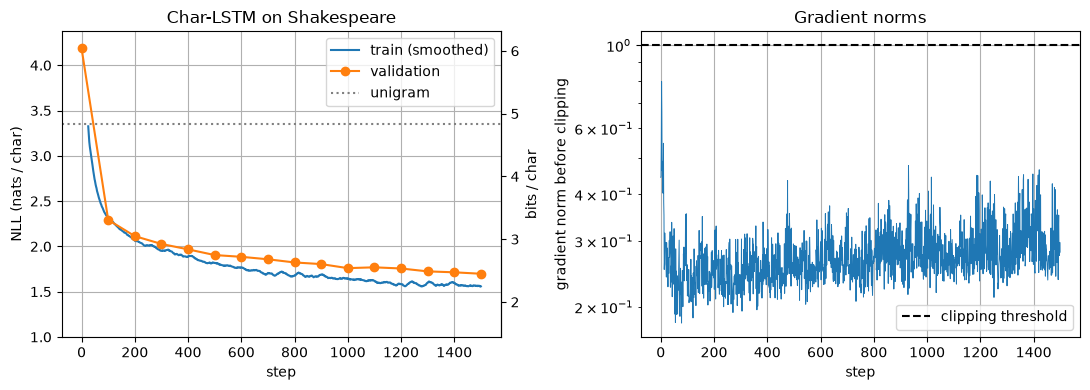

LSTM, full validation set: 1.712 nats/char = 2.470 bits/char, perplexity 5.54


In [9]:
def smooth(a, k=25):
    a = np.asarray(a)
    return np.convolve(a, np.ones(k) / k, mode="valid")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.plot(np.arange(len(smooth(hist_lstm["train"]))) + 25, smooth(hist_lstm["train"]), label="train (smoothed)")
ax.plot(*zip(*hist_lstm["val"]), "o-", label="validation")
ax.axhline(unigram_nll, color="gray", ls=":", label="unigram")
ax.set_ylim(1.0, math.log(V) + 0.2)
ax.set_xlabel("step"); ax.set_ylabel("NLL (nats / char)"); ax.set_title("Char-LSTM on Shakespeare")
sec = ax.secondary_yaxis("right", functions=(lambda n: n / math.log(2), lambda b: b * math.log(2)))
sec.set_ylabel("bits / char")
ax.legend()
axes[1].plot(hist_lstm["grad_norm"], lw=0.7)
axes[1].axhline(1.0, color="k", ls="--", label="clipping threshold")
axes[1].set_yscale("log"); axes[1].set_xlabel("step"); axes[1].set_ylabel("gradient norm before clipping")
axes[1].legend(); axes[1].set_title("Gradient norms")
plt.tight_layout(); plt.show()

val_nll_lstm, _ = evaluate(lstm, val_ids)
print(f"LSTM, full validation set: {val_nll_lstm:.3f} nats/char = {val_nll_lstm / math.log(2):.3f} bits/char,"
      f" perplexity {math.exp(val_nll_lstm):.2f}")

A perplexity of $e^{\text{NLL}}$ means the model is, on average, as uncertain as if it were choosing
uniformly between that many characters — down from 65. Training and validation curves stay
close: with ~1 M characters and ~200 k parameters, a few epochs do not overfit (compare LM 5,
where the word-level model overfitted quickly). Bigger models trained for longer reach about
1.4–1.5 nats/char on this split; we are compute-limited, not data-limited.

## 5. What the model learns, in order

The samples generated during training show the classical progression of a character model:
first the character *frequencies* (lots of spaces and `e`s), then *word shapes* and line
breaks, then the *format* of a play (speaker names followed by a colon and a newline), and
finally real words and fragments of grammar.

In [10]:
for step, s in hist_lstm["samples"].items():
    print(f"========== after {step} steps ==========")
    print(s.strip("\n"))
    print()

========== after 0 steps ==========
Caw;suqW
.&TTNUSuOgl,O,cKavjeXLZ&Kf .UK.msowgKPXDcvLf;KvVSKz3 GvOW$N!r.CLIoxZJWXoaF$XgaMFNZwjV's$:TpgrKdgPfZNLyJo&Bd:DB tV3SnRbqQ's:VhYToKSVvErdv$PkO:HTy!JUXhd-R$mNcCmOH$bk AzwVi'VRLCfNLDLFfZ,w!BUQHC

========== after 50 steps ==========
Caw;sull
.:TTNUSuIgl, thastme, bo faces.
Bow trou vy thearthc heem,
ira miox, aroflfnganee, hees nongrit of fongor dous therisbe


:ahist terErdvees meas arest avehcram sou iswer' eltis telft, it rea

========== after 200 steps ==========
BCuw;st Werents aus leath atmeron a ace wos wintsing freear, cadest,
Hearl. xain half gaies, hees not with fould or dous theringel'ss?
Yous therdvers, Heard ast gamecran sou is the elding the , it rea

========== after 600 steps ==========
CCaUTon:

MARTIUS:
Me, that me, by face hose go'd calf that in herm,
Hearl. O, a havengaies, whes not with fould of do
Byt this yous as fot thereveds,
Hay! Yest gomectan to the him elving ouft, it rec

========== after 1500 steps ==========
Course

## 6. Does the carried state help?

We trained with a carried state. At test time we can either keep carrying it, or reset it every
$T = 64$ characters (which is what a model trained on random windows would have to do). The
right-hand plot shows the loss as a function of the position inside a 64-character chunk when
the state is reset: right after a reset the model knows nothing and its loss is close to the
unigram level; it needs a few dozen characters to "get into" the text again.

carried state      : 1.712 nats/char
reset every 64 chars: 1.797 nats/char


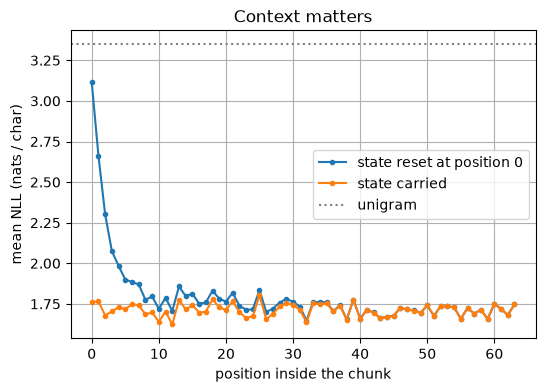

In [11]:
nll_carry, pos_carry = evaluate(lstm, val_ids, T=64, carry=True)
nll_reset, pos_reset = evaluate(lstm, val_ids, T=64, carry=False)
print(f"carried state      : {nll_carry:.3f} nats/char")
print(f"reset every 64 chars: {nll_reset:.3f} nats/char")

plt.figure(figsize=(6, 4))
plt.plot(pos_reset, ".-", label="state reset at position 0")
plt.plot(pos_carry, ".-", label="state carried")
plt.axhline(unigram_nll, color="gray", ls=":", label="unigram")
plt.xlabel("position inside the chunk"); plt.ylabel("mean NLL (nats / char)")
plt.title("Context matters"); plt.legend(); plt.show()

Even though the gradient never flowed across more than 64 steps, the network uses information
from further back: the carried state gives a lower loss than resets. The first few characters
after a reset are by far the most expensive — exactly the context problem a Transformer has at
the start of its window (LM 8), and the reason LLM evaluations use **sliding windows**.

## 7. RNN vs GRU vs LSTM

We now train a vanilla `nn.RNN` (tanh) and an `nn.GRU` with the same embedding size, hidden size,
optimiser, learning rate, clipping and data order for a short budget of 400 steps. For the LSTM
we reuse the first 400 steps of the run above: the learning rate is constant and the chunk order
deterministic, so they are exactly a 400-step run.

cell      params  ms/step  val NLL  bits/char
rnn       66,241        9    1.921      2.771
gru      165,313       23    1.821      2.626
lstm     214,849       11    1.967      2.838


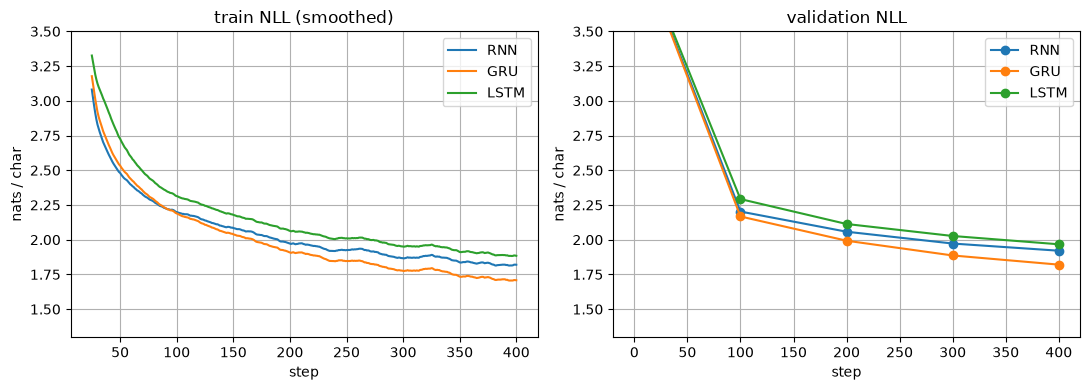

In [12]:
COMPARE_STEPS = 400
results = {}
for cell in ("rnn", "gru"):
    torch.manual_seed(0)
    model = CharRNN(V, cell)
    h = train(model, COMPARE_STEPS, verbose=False)
    results[cell] = dict(hist=h, val=h["val"][-1][1], params=sum(p.numel() for p in model.parameters()),
                         ms=1000 * h["time"][-1] / COMPARE_STEPS)
results["lstm"] = dict(
    hist={"train": hist_lstm["train"][:COMPARE_STEPS],
          "val": [(s, v) for s, v in hist_lstm["val"] if s <= COMPARE_STEPS]},
    val=dict(hist_lstm["val"])[COMPARE_STEPS], params=sum(p.numel() for p in lstm.parameters()),
    ms=1000 * hist_lstm["time"][COMPARE_STEPS - 1] / COMPARE_STEPS)

print(f"{'cell':6s} {'params':>9s} {'ms/step':>8s} {'val NLL':>8s} {'bits/char':>10s}")
for cell in ("rnn", "gru", "lstm"):
    r = results[cell]
    print(f"{cell:6s} {r['params']:9,d} {r['ms']:8.0f} {r['val']:8.3f} {r['val'] / math.log(2):10.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for cell in ("rnn", "gru", "lstm"):
    h = results[cell]["hist"]
    axes[0].plot(np.arange(len(smooth(h["train"]))) + 25, smooth(h["train"]), label=cell.upper())
    axes[1].plot(*zip(*h["val"]), "o-", label=cell.upper())
for ax, title in zip(axes, ("train NLL (smoothed)", "validation NLL")):
    ax.set_xlabel("step"); ax.set_ylabel("nats / char"); ax.set_title(title); ax.set_ylim(1.3, 3.5); ax.legend()
plt.tight_layout(); plt.show()

With equal hidden size the three cells differ in parameters (the GRU has 3 and the LSTM 4 weight
blocks per vanilla-RNN block) and in time per step. The ranking after 400 steps may surprise you:
in our run the GRU is ahead, and the LSTM is *behind* even the vanilla RNN. This is a statement
about **speed of learning**, not about capacity. The LSTM has the most parameters and a cell state
that starts out empty, so it needs more steps to get going; look at the training curve of
Section 4, where the same LSTM keeps improving to about 1.71 nats/char after 1500 steps. The
vanilla RNN is not hopeless at character level either — most of what matters is within a few
characters — but its gradient through time vanishes (Lecture 7), so it gains little from longer
memory and plateaus earlier.

The lesson generalises to LLM research: **comparisons at a tiny budget can rank models in the
opposite order to comparisons at a large one.** A fair comparison fixes the budget that matters
(steps, parameters, wall-clock time or FLOPs) and checks more than one point. Try it: rerun the
comparison with 1500 steps, or with hidden sizes chosen to equalise the parameter count.

## 8. Generating text: temperature, top-$k$ and prompts

Generation repeats: compute $p(c_{t+1}\mid c_{\le t})$, sample a character, feed it back in.
Two knobs control the trade-off between *quality* and *diversity*:

* **Temperature** $\tau$: sample from $\operatorname{softmax}(\mathbf{z}/\tau)$. Small $\tau$ sharpens
  the distribution (safe, repetitive), large $\tau$ flattens it (creative, then garbled).
* **Top-$k$**: keep only the $k$ most probable characters, renormalise, sample. This removes the
  long tail of individually unlikely characters which, *collectively*, are sampled surprisingly
  often and derail the text (one bad character can break a word).

A **prompt** ("priming") is simply a prefix we feed through the network before sampling; the
state then encodes it. With the prompt `ROMEO:` the model should continue with a newline and
a speech, because that is what follows a name and a colon in the training data.

In [13]:
torch.manual_seed(0)
for tau, k in [(0.5, None), (1.0, None), (1.5, None), (1.0, 5)]:
    label = f"temperature {tau}" + (f", top-k {k}" if k else "")
    print(f"========== {label} ==========")
    print(sample(lstm, "ROMEO:", 300, temperature=tau, top_k=k, seed=2))
    print()

========== temperature 0.5 ==========
ROMEO: day, look;
We strather that more to such with a bedient
To have do are the batts thee, marrent than thee be day's and father
That dain the say, for the villicion.

POMPEY:
Come, that have satis call the bart with the death
When it come the light that with me to the hands.

KING RICHARD III:
The war

========== temperature 1.0 ==========


ROMEO: day, lood;
We'ly you to say moorn, by than you ween made day his
share the batts water! I reveng and cheabes
I 'tis tongue than the surps is ellow cad
With him, cad his graving madl make wift?

PERIY:
And I am that not repothes in commolain,
To despit, and bettruph him that brother father-never
Mad

========== temperature 1.5 ==========
ROMEO: dvently,
Ry, her you'to!. Unviosers.
Sisan ye. when know day hoid mees tle'bla, up.

Kwhat.

KING PERZET:
My me't--nembly; folkbled surps. With do crim;
He I mudchal; lightling'st lux
to woft? I mude;'g;
Con, mUD tongerraties.

MENENIUS:
Well
Slay! to jaunt? O, that you arfell! gieffate!.-nat.

MEN

========== temperature 1.0, top-k 5 ==========
ROMEO: them at may,
I'll be to say a dear their would we most death of dread
Will bather too, marrent that should be soul tend
To than the surple of thou still.

LEONTES:
He have thank that have satis welded most of the hand
Tracking of make of to to makes trial he did;
What stand the present of th

The effect of the two knobs on a single next-character distribution:

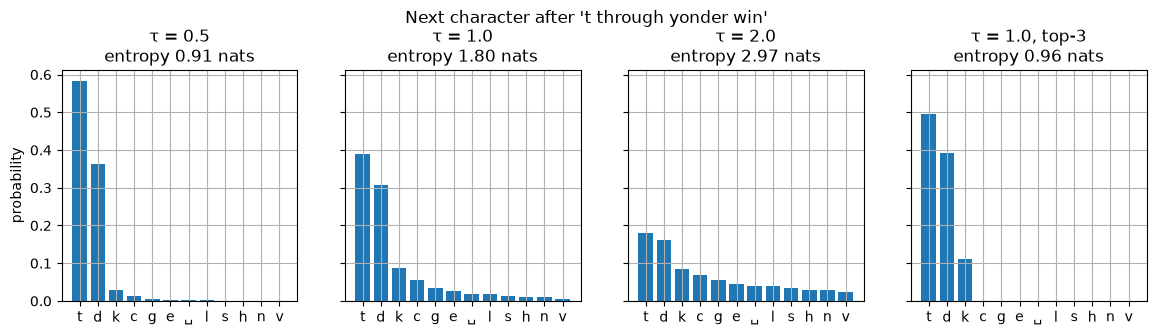

In [14]:
prompt = "ROMEO:\nWhat light through yonder win"
with torch.no_grad():
    lstm.eval()
    z = lstm(torch.tensor([encode(prompt)], device=device))[0][0, -1].cpu()
top = torch.argsort(z, descending=True)[:12]
labels = [{" ": "␣", "\n": "\\n"}.get(itos[i], itos[i]) for i in top.tolist()]
fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, (tau, k) in zip(axes, [(0.5, None), (1.0, None), (2.0, None), (1.0, 3)]):
    zz = z / tau
    if k is not None:
        zz = zz.masked_fill(zz < torch.topk(zz, k).values[-1], float("-inf"))
    p = F.softmax(zz, dim=-1)
    ent = -(p[p > 0] * torch.log(p[p > 0])).sum().item()
    ax.bar(labels, p[top].numpy())
    ax.set_title(f"τ = {tau}" + (f", top-{k}" if k else "") + f"\nentropy {ent:.2f} nats")
axes[0].set_ylabel("probability")
plt.suptitle(f"Next character after {prompt[-20:]!r}", y=1.08); plt.show()

## 9. Inside the LSTM: what do individual units track?

Karpathy, Johnson & Fei-Fei (2015) found that some LSTM cells in character models are directly
**interpretable**: one unit counts the position within a line, another switches on inside
quotes, another tracks the nesting depth of brackets in code. Let us look for such a unit. We run
the trained LSTM one character at a time over a piece of validation text, record the cell state
$\mathbf{c}_t \in \mathbb{R}^{H}$ at every step, and correlate each unit with the *position of the
character in its line* (characters since the last newline).

With a small model and a short budget we should not expect a perfect "line-length counter", but
usually some unit correlates clearly with it — after all, Shakespeare's verse lines have a
characteristic length, and predicting the newline requires knowing where in the line we are.

unit 182: correlation with position-in-line r = +0.82


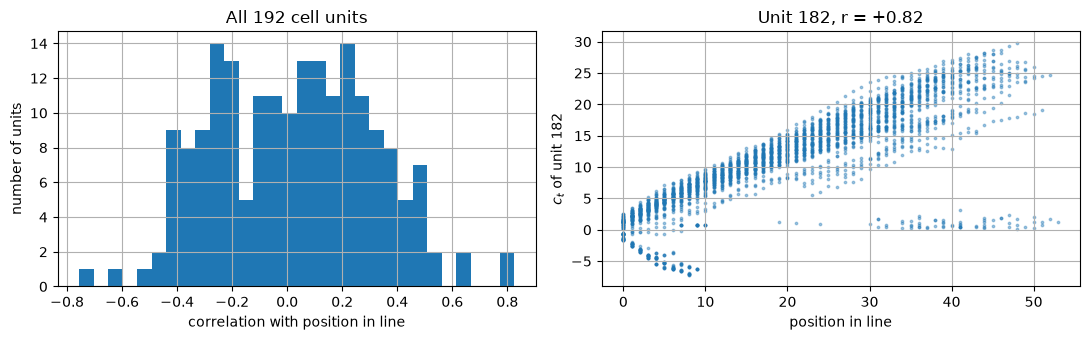

In [15]:
@torch.no_grad()
def lstm_cell_states(model, ids):
    """Run the LSTM character by character and return the cell states c_t, shape (N, H)."""
    model.eval()
    emb = model.emb(torch.tensor([ids], dtype=torch.long, device=device))   # (1, N, E)
    state, cs = None, []
    for t in range(emb.size(1)):
        _, state = model.rnn(emb[:, t:t + 1], state)                        # state = (h, c), each (1, 1, H)
        cs.append(state[1][0, 0])
    model.train()
    return torch.stack(cs).cpu().numpy()

probe_text = val_text[:3000]
C = lstm_cell_states(lstm, encode(probe_text))                             # (3000, H)
line_pos = np.zeros(len(probe_text))
col = 0
for t, ch in enumerate(probe_text):
    line_pos[t] = col
    col = 0 if ch == "\n" else col + 1

corr = np.array([np.corrcoef(C[:, j], line_pos)[0, 1] if C[:, j].std() > 1e-6 else 0.0
                 for j in range(C.shape[1])])
best = int(np.nanargmax(np.abs(corr)))
print(f"unit {best}: correlation with position-in-line r = {corr[best]:+.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(corr, bins=30)
axes[0].set_xlabel("correlation with position in line"); axes[0].set_ylabel("number of units")
axes[0].set_title(f"All {C.shape[1]} cell units")
axes[1].scatter(line_pos, C[:, best], s=3, alpha=0.4)
axes[1].set_xlabel("position in line"); axes[1].set_ylabel(f"$c_t$ of unit {best}")
axes[1].set_title(f"Unit {best}, r = {corr[best]:+.2f}")
plt.tight_layout(); plt.show()

And the same unit drawn over the text itself (red = high, blue = low), in the style of
Karpathy's blog post *The unreasonable effectiveness of recurrent neural networks*:

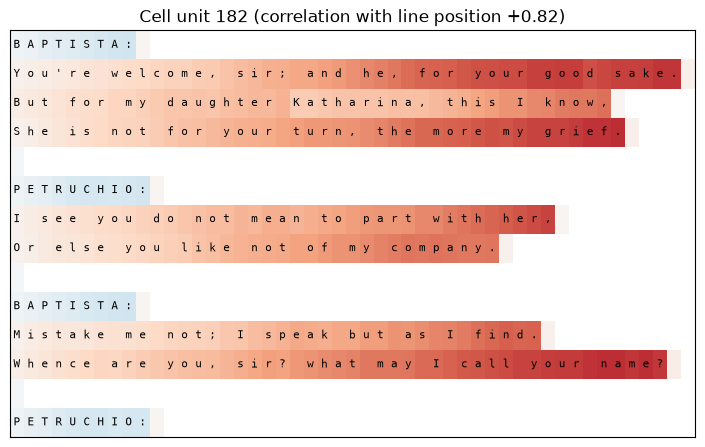

In [16]:
def show_unit(text_piece, act, title, max_lines=14):
    lines = text_piece.split("\n")[:max_lines]
    width = max(len(l) for l in lines) + 1
    grid = np.full((len(lines), width), np.nan)
    t = 0
    for r, line in enumerate(lines):
        for c in range(len(line) + 1):                 # +1: the newline that ends the line
            if t < len(act):
                grid[r, c] = act[t]
            t += 1
    lim = 1.4 * np.nanpercentile(np.abs(act[:t]), 98) + 1e-6       # a bit wider, keeps the text readable
    fig, ax = plt.subplots(figsize=(0.16 * width + 1, 0.32 * len(lines) + 0.8))
    ax.imshow(grid, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    for r, line in enumerate(lines):
        for c, ch in enumerate(line):
            ax.text(c, r, ch, ha="center", va="center", fontsize=8, family="monospace")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(title)
    plt.show()

start = probe_text.find("\n\n", 500) + 2                # start the excerpt at the beginning of a speech
show_unit(probe_text[start:], C[start:, best], f"Cell unit {best} (correlation with line position {corr[best]:+.2f})")

Look for a unit that ramps up (or down) along each line and snaps back after the newline. If your
best unit is noisy, that is a real finding too: in small networks most units are **polysemantic**
— they mix several features — and clean single-unit features are the exception. Modern
interpretability research on LLMs (sparse autoencoders, "features" and "circuits") is the
descendant of exactly this experiment.

## 10. Result

In [17]:
assert val_nll_lstm < 2.5, val_nll_lstm
print(f"val NLL (nats/char): {val_nll_lstm:.3f}")
print(f"val bits/char:       {val_nll_lstm / math.log(2):.3f}")

val NLL (nats/char): 1.712
val bits/char:       2.470


## From here to LLMs

* **Streaming long text with a state** is how RNN LMs were trained for two decades — and it has
  come back. *Transformer-XL* (Dai et al., 2019) caches the hidden states of the previous segment
  and attends to them *with gradients stopped*: precisely our "carry and detach". Modern
  **state-space models and linear-attention models** (Mamba, RWKV, xLSTM) are recurrent networks
  with a fixed-size state that can be trained in parallel and run in $O(1)$ memory per generated
  token.
* **Truncated context** is the RNN version of the Transformer's **context window**: LLMs train on
  documents cut into fixed-length windows, and the loss at the start of each window is higher
  (Section 6). That is why perplexities are reported with sliding-window evaluation.
* **Bits per character / byte** is still how LLMs are compared across different tokenisers
  (LM 8 converts a BPE model's loss to nats per character for exactly this reason).
* **Temperature and top-$k$** are the same knobs exposed by every LLM API today, joined by
  **top-$p$** (nucleus) sampling, which we implement in LM 8.
* **Interpretable units** led to the field of mechanistic interpretability; in LLMs, single neurons
  are mostly polysemantic, and features are found as *directions* in activation space instead.
* Before Transformers, the strongest LMs were large multi-layer LSTMs trained exactly like this
  (Jozefowicz et al., 2016). Their weakness — strictly **sequential** processing within a chunk —
  is what self-attention removes (LM 8).

## Try it yourself

1. Train with the state **reset** at every chunk (replace `detach_state` by `None`) and compare the
   validation NLL with carried state. Then vary $T \in \{16, 64, 256\}$.
2. Use two stacked LSTM layers (`num_layers=2`, add dropout between them) and compare with a single
   layer of the same parameter count. Remember that the state now has shape $(2, B, H)$.
3. Redo Section 7 with **equal parameter counts** (larger $H$ for the RNN) or equal wall-clock
   time. Does the ranking change?
4. Remove gradient clipping (or set it to 100) and train the vanilla RNN with a larger learning
   rate. Plot the gradient norms.
5. Find a unit that responds to something else: the first line of a speech, a speaker name, or
   capital letters. Correlate all units with your feature and draw the best one with `show_unit`.
6. Train on a different text (your own notes, code, another language) and look at the samples.

**Further reading.**
Elman (1990), *Finding structure in time*;
Hochreiter & Schmidhuber (1997), *Long short-term memory*;
Cho et al. (2014), *Learning phrase representations using RNN encoder–decoder* (GRU);
Graves (2013), *Generating sequences with recurrent neural networks*;
Sutskever, Martens & Hinton (2011), *Generating text with recurrent neural networks*;
Karpathy (2015), *The unreasonable effectiveness of recurrent neural networks* (blog post, and `char-rnn`);
Karpathy, Johnson & Fei-Fei (2015), *Visualizing and understanding recurrent networks*;
Jozefowicz et al. (2016), *Exploring the limits of language modeling*;
Dai et al. (2019), *Transformer-XL*;
Holtzman et al. (2020), *The curious case of neural text degeneration* (sampling strategies).